In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix


**Data:** Meteorite Landings, from The Meteoritical Society, published by NASA.
https://data.nasa.gov/dataset/meteorite-landings
Thanks to both for making it publicly available.

In [69]:
df = pd.read_csv('../data/Meteorite_Landings.csv')
print(df.shape)
print(df.columns.tolist())
display(pd.concat([df.head(), df.tail()]))

(45716, 10)
['name', 'id', 'nametype', 'recclass', 'mass (g)', 'fall', 'year', 'reclat', 'reclong', 'GeoLocation']


,name,id,nametype,recclass,mass (g),fall,year,reclat,reclong,GeoLocation
0,Aachen,1,Valid,L5,21.0,Fell,1880.0,50.77500,6.08333,"(50.775, 6.08333)"
1,Aarhus,2,Valid,H6,720.0,Fell,1951.0,56.18333,10.23333,"(56.18333, 10.23333)"
2,Abee,6,Valid,EH4,107000.0,Fell,1952.0,54.21667,-113.00000,"(54.21667, -113.0)"
3,Acapulco,10,Valid,Acapulcoite,1914.0,Fell,1976.0,16.88333,-99.90000,"(16.88333, -99.9)"
4,Achiras,370,Valid,L6,780.0,Fell,1902.0,-33.16667,-64.95000,"(-33.16667, -64.95)"
45711,Zillah 002,31356,Valid,Eucrite,172.0,Found,1990.0,29.03700,17.01850,"(29.037, 17.0185)"
45712,Zinder,30409,Valid,"Pallasite, ungrouped",46.0,Found,1999.0,13.78333,8.96667,"(13.78333, 8.96667)"
45713,Zlin,30410,Valid,H4,3.3,Found,1939.0,49.25000,17.66667,"(49.25, 17.66667)"
45714,Zubkovsky,31357,Valid,L6,2167.0,Found,2003.0,49.78917,41.50460,"(49.78917, 41.5046)"
45715,Zulu Queen,30414,Valid,L3.7,200.0,Found,1976.0,33.98333,-115.68333,"(33.98333, -115.68333)"


In [56]:
df.isnull().sum()

name              0
id                0
nametype          0
recclass          0
mass (g)        131
fall              0
year            291
reclat         7315
reclong        7315
GeoLocation    7315
dtype: int64

In [57]:
df.duplicated(subset=['id']).sum()

np.int64(0)

In [58]:
df['no_coords'] = df['reclat'].isnull()
print(df.groupby('no_coords')['fall'].value_counts(normalize=True))
print(df['nametype'].value_counts())
print(df['year'].describe())
print("lat/long both 0:", ((df['reclat'] == 0) & (df['reclong'] == 0)).sum())

no_coords  fall 
False      Found    0.971433
           Fell     0.028567
True       Found    0.998633
           Fell     0.001367
Name: proportion, dtype: float64
nametype
Valid     45641
Relict       75
Name: count, dtype: int64
count    45425.000000
mean      1991.828817
std         25.052766
min        860.000000
25%       1987.000000
50%       1998.000000
75%       2003.000000
max       2101.000000
Name: year, dtype: float64
lat/long both 0: 6214


In [59]:
df_clean = df[df['nametype'] == 'Valid'].copy()
df_clean = df_clean.dropna(subset=['mass (g)', 'year', 'reclat', 'reclong'])
df_clean = df_clean[df_clean['mass (g)'] > 0]
df_clean = df_clean[df_clean['year'] <= 2026]
df_clean = df_clean[~((df_clean['reclat'] == 0) & (df_clean['reclong'] == 0))]

df_clean['fell'] = (df_clean['fall'] == 'Fell').astype(int)
df_clean['log_mass'] = np.log10(df_clean['mass (g)'])
df_clean['abs_lat'] = df_clean['reclat'].abs()

print(df_clean.shape)
print(df_clean['fell'].value_counts())

(31908, 14)
fell
0    30844
1     1064
Name: count, dtype: int64


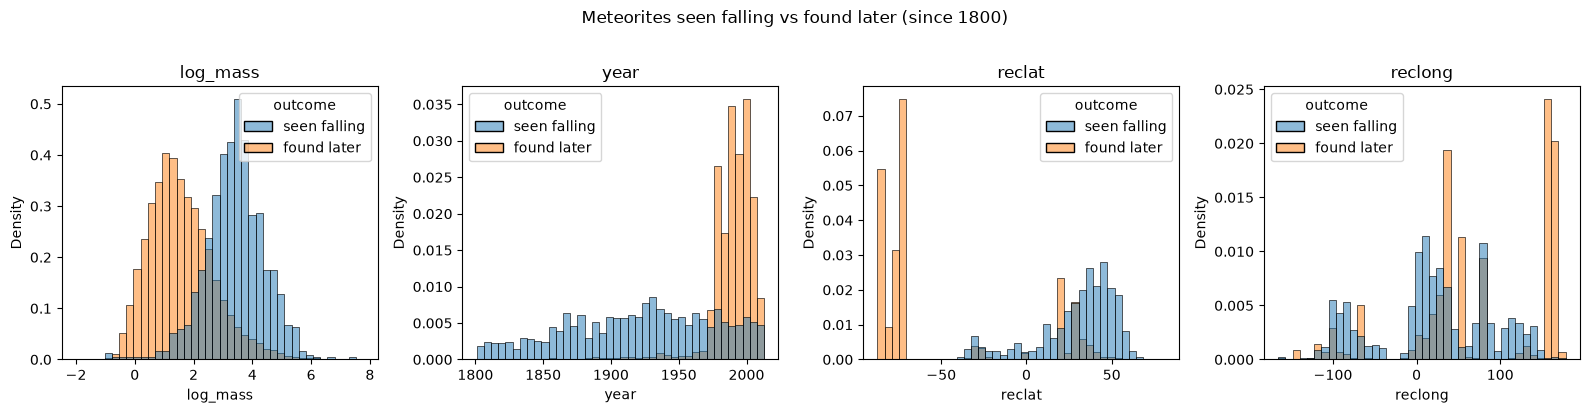

In [68]:
plot_df = df_clean[df_clean['year'] >= 1800].copy()
plot_df['outcome'] = plot_df['fell'].map({0: 'found later', 1: 'seen falling'})

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['log_mass', 'year', 'reclat', 'reclong']):
    sns.histplot(data=plot_df, x=col, hue='outcome', stat='density',
                 common_norm=False, bins=40, ax=ax)
    ax.set_title(col)
fig.suptitle('Meteorites seen falling vs found later (since 1800)', y=1.02)
plt.tight_layout()
plt.show()

In [62]:
features = ['log_mass', 'year', 'reclat', 'reclong']
X = df_clean[features]
y = df_clean['fell']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=2000, random_state=1)
)
model.fit(X_train, y_train)

pred  = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

In [64]:
model.score(X_test, y_test)


0.9172673143215293

In [70]:
pred  = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]


In [65]:
print(classification_report(y_test, pred, target_names=['found', 'fell']))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("Confusion matrix (rows = actual, cols = predicted):")
print(confusion_matrix(y_test, pred))
coefs = model.named_steps['logisticregression'].coef_[0]
print(pd.DataFrame({
    'feature': features,
    'coef': coefs.round(3),
    'odds_ratio': np.exp(coefs).round(3)
}))

              precision    recall  f1-score   support

       found       1.00      0.92      0.96      6169
        fell       0.28      0.92      0.43       213

    accuracy                           0.92      6382
   macro avg       0.64      0.92      0.69      6382
weighted avg       0.97      0.92      0.94      6382

ROC-AUC: 0.965
Confusion matrix (rows = actual, cols = predicted):
[[5657  512]
 [  16  197]]
    feature   coef  odds_ratio
0  log_mass  0.949       2.583
1      year -1.037       0.355
2    reclat  1.567       4.791
3   reclong  0.216       1.241
